# Experimento 2: ¿cuándo es exacto el total de una búsqueda?

Datos de vuelos de ejemplo — Pablo Adasme

[Volver al índice](00_indice.ipynb)

## Conexión compartida

Ejecuta esta celda primero. Desde Jupyter en Docker Compose, usa `http://elasticsearch:9200`; si el kernel corre en el equipo anfitrión, usa `http://localhost:9200`.

El índice de vuelos de ejemplo debe existir. Todas las peticiones son de solo lectura: el cuaderno no instala datos ni modifica el clúster.

In [16]:
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

url_elasticsearch = "http://elasticsearch:9200"
indice = "kibana_sample_data_flights"


def consultar(endpoint, cuerpo):
    url = f"{url_elasticsearch.rstrip('/')}/{indice}/{endpoint}"
    cuerpo_json = json.dumps(cuerpo, ensure_ascii=False, indent=2)
    print(f"GET {url}\n{cuerpo_json}")
    solicitud = Request(url, data=cuerpo_json.encode("utf-8"),
                        headers={"Content-Type": "application/json"}, method="GET")
    try:
        with urlopen(solicitud, timeout=10) as respuesta:
            datos = json.load(respuesta)
    except HTTPError as error:
        print(f"Error HTTP {error.code}. Revisa el índice y la consulta.")
        return None
    except (URLError, TimeoutError):
        print("No se pudo conectar con Elasticsearch. Revisa la URL y el servicio.")
        return None
    except (ValueError, OSError):
        print("No se pudo leer la respuesta de Elasticsearch.")
        return None

    fragmentos = datos.get("_shards") if isinstance(datos, dict) else None
    if (not isinstance(fragmentos, dict)
            or fragmentos.get("failed") != 0
            or type(fragmentos.get("total")) is not int
            or fragmentos["total"] <= 0
            or fragmentos.get("successful") != fragmentos["total"]
            or datos.get("timed_out", False)
            or datos.get("terminated_early", False)):
        print("Respuesta incompleta: no se pudo confirmar el resultado de todos los fragmentos.")
        return None
    return datos


totales = {}


def medir_total(etiqueta, cuerpo):
    totales.pop(etiqueta, None)
    respuesta = consultar("_search?allow_partial_search_results=false", cuerpo)
    if respuesta is None:
        return
    hits = respuesta.get("hits")
    total = hits.get("total") if isinstance(hits, dict) else None
    if (respuesta.get("timed_out") is not False
            or not isinstance(total, dict)
            or type(total.get("value")) is not int
            or total["value"] < 0
            or total.get("relation") not in ("gte", "eq")
            or hits.get("hits") != []
            or (cuerpo["track_total_hits"] is True and total["relation"] != "eq")):
        print("Respuesta inválida para esta medición.")
        return
    valor, relacion = total["value"], total["relation"]
    totales[etiqueta] = valor, relacion
    print(f"hits.total: valor = {valor}, relación = {relacion}")

## Qué se mide

Las tres búsquedas usan el mismo índice, el destino `AU` y el intervalo de `AvgTicketPrice` **[500, 950)**: incluye 500 y excluye 950. `size: 0` evita devolver vuelos individuales, pero la respuesta aún incluye `hits.total`.

**Solo cambia `track_total_hits`**: un entero bajo (10), un entero alto (1000) y `true`. Lee `hits.total.value` junto con `hits.total.relation`: `gte` significa «al menos» y `eq` significa «exactamente».

En Jupyter, ejecuta la conexión y luego las tres mediciones en cualquier orden. Si repites una medición, vuelve a ejecutar la comparación: un intento fallido invalida su resultado previo. Volver a ejecutar la conexión reinicia las tres mediciones. En Kibana (`http://localhost:5601`), copia cada petición completa en Dev Tools. Conserva el índice sin cambios entre las mediciones.

### Medición 1: Umbral bajo (`10`)

```http
GET kibana_sample_data_flights/_search?allow_partial_search_results=false
{
  "size": 0,
  "track_total_hits": 10,
  "query": {
    "bool": {
      "filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 950}}}
      ]
    }
  }
}
```

In [17]:
medir_total("10", {
    "size": 0,
    "track_total_hits": 10,
    "query": {"bool": {"filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 950}}},
    ]}},
})

GET http://elasticsearch:9200/kibana_sample_data_flights/_search?allow_partial_search_results=false
{
  "size": 0,
  "track_total_hits": 10,
  "query": {
    "bool": {
      "filter": [
        {
          "term": {
            "DestCountry": "AU"
          }
        },
        {
          "range": {
            "AvgTicketPrice": {
              "gte": 500,
              "lt": 950
            }
          }
        }
      ]
    }
  }
}
hits.total: valor = 10, relación = gte


### Medición 2: Umbral alto (`1000`)

```http
GET kibana_sample_data_flights/_search?allow_partial_search_results=false
{
  "size": 0,
  "track_total_hits": 1000,
  "query": {
    "bool": {
      "filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 950}}}
      ]
    }
  }
}
```

In [18]:
medir_total("1000", {
    "size": 0,
    "track_total_hits": 1000,
    "query": {"bool": {"filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 950}}},
    ]}},
})

GET http://elasticsearch:9200/kibana_sample_data_flights/_search?allow_partial_search_results=false
{
  "size": 0,
  "track_total_hits": 1000,
  "query": {
    "bool": {
      "filter": [
        {
          "term": {
            "DestCountry": "AU"
          }
        },
        {
          "range": {
            "AvgTicketPrice": {
              "gte": 500,
              "lt": 950
            }
          }
        }
      ]
    }
  }
}
hits.total: valor = 242, relación = eq


### Medición 3: Conteo exacto (`true`)

```http
GET kibana_sample_data_flights/_search?allow_partial_search_results=false
{
  "size": 0,
  "track_total_hits": true,
  "query": {
    "bool": {
      "filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 950}}}
      ]
    }
  }
}
```

In [19]:
medir_total("true", {
    "size": 0,
    "track_total_hits": True,
    "query": {"bool": {"filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 950}}},
    ]}},
})

GET http://elasticsearch:9200/kibana_sample_data_flights/_search?allow_partial_search_results=false
{
  "size": 0,
  "track_total_hits": true,
  "query": {
    "bool": {
      "filter": [
        {
          "term": {
            "DestCountry": "AU"
          }
        },
        {
          "range": {
            "AvgTicketPrice": {
              "gte": 500,
              "lt": 950
            }
          }
        }
      ]
    }
  }
}
hits.total: valor = 242, relación = eq


### Bloque 4: comparación y visualización

El círculo relleno marca un total exacto. El círculo vacío con flecha hacia la derecha marca un límite inferior, no una estimación del total. La comparación requiere tres respuestas válidas y compatibles con la referencia exacta de `true`.

| `track_total_hits` | `value` | `relation` | Lectura |
| --- | ---: | --- | --- |
| `10` | 10 | `gte` | Al menos 10 |
| `1000` | 242 | `eq` | Exactamente 242 |
| `true` | 242 | `eq` | Exactamente 242 |

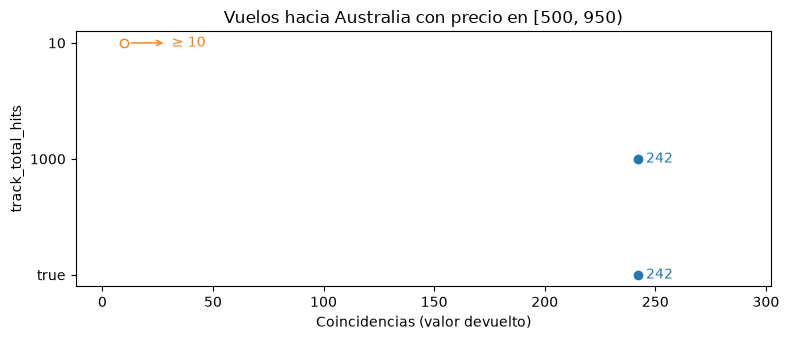

In [20]:
etiquetas_total = ("10", "1000", "true")
if any(etiqueta not in totales for etiqueta in etiquetas_total):
    print("No se puede comparar: ejecuta o repite las mediciones sin resultado válido.")
else:
    referencia = totales["true"][0]
    if any(valor != referencia if relacion == "eq" else valor > referencia
           for valor, relacion in totales.values()):
        print("Resultados incompatibles: reinicia las mediciones con el mismo índice sin cambios.")
    else:
        filas = ["| `track_total_hits` | `value` | `relation` | Lectura |",
                 "| --- | ---: | --- | --- |"]
        fig, ax = plt.subplots(figsize=(8, 3.5))
        for y, etiqueta in enumerate(etiquetas_total):
            valor, relacion = totales[etiqueta]
            exacto = relacion == "eq"
            lectura = f"Exactamente {valor}" if exacto else f"Al menos {valor}"
            filas.append(f"| `{etiqueta}` | {valor} | `{relacion}` | {lectura} |")
            color = "tab:blue" if exacto else "tab:orange"
            ax.scatter(valor, y, facecolors=color if exacto else "white",
                       edgecolors=color, zorder=3)
            if not exacto:
                # La flecha indica dirección; su longitud no representa un conteo.
                ax.annotate("", xy=(valor, y), xytext=(30, 0), textcoords="offset points",
                            arrowprops={"arrowstyle": "<-", "color": color, "shrinkB": 5})
            ax.annotate(f"{valor}" if exacto else f"≥ {valor}", (valor, y),
                        xytext=(6 if exacto else 34, 0), textcoords="offset points",
                        va="center", color=color)
        display(Markdown("\n".join(filas)))
        ax.set_yticks(range(len(etiquetas_total)), etiquetas_total)
        ax.invert_yaxis()
        ax.set_xlim(-max(1, referencia * 0.05), max(1, referencia * 1.25))
        ax.set(xlabel="Coincidencias (valor devuelto)", ylabel="track_total_hits",
               title="Vuelos hacia Australia con precio en [500, 950)")
        fig.tight_layout()
        plt.show()

#### Conclusión observada

En el índice local de ejemplo, `10` devolvió **10 (`gte`)**: la búsqueda confirmó al menos 10 coincidencias, no que hubiera exactamente 10. Tanto `1000` como `true` devolvieron **242 (`eq`)**. Hubo 242 coincidencias para el filtro fijo, y el umbral alto no limitó ese conteo. Esta comparación demuestra la diferencia entre un límite inferior y un total exacto para estos datos.

## Anexo A (opcional): conteos por intervalo con `/_count`

Este ejemplo responde otra pregunta: ¿cuál de los tres intervalos contiene más vuelos con destino a Australia? Aquí sí cambia el filtro de precio. Los intervalos tienen la misma amplitud (150 unidades) y no se solapan: `gte` incluye el límite inferior y `lt` excluye el superior.

En Jupyter, ejecuta la conexión compartida y la preparación del anexo antes de sus tres mediciones. Para usar Dev Tools, copia la petición completa de cada intervalo.

In [ ]:
pais_destino = "AU"
intervalos = [(500, 650), (650, 800), (800, 950)]
conteos = {}


def medir(inferior, superior):
    conteos.pop((inferior, superior), None)
    cuerpo = {"query": {"bool": {"filter": [
        {"term": {"DestCountry": pais_destino}},
        {"range": {"AvgTicketPrice": {"gte": inferior, "lt": superior}}},
    ]}}}
    resultado = consultar("_count", cuerpo)
    if resultado is None:
        return
    conteo = resultado.get("count")
    if type(conteo) is not int or conteo < 0:
        print("La respuesta no contiene un conteo válido.")
        return
    conteos[inferior, superior] = conteo
    print(f"Vuelos en [{inferior}, {superior}): {conteo}")

### Medición 1: [500, 650)

```http
GET kibana_sample_data_flights/_count
{
  "query": {
    "bool": {
      "filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 500, "lt": 650}}}
      ]
    }
  }
}
```

In [ ]:
medir(*intervalos[0])

### Medición 2: [650, 800)

```http
GET kibana_sample_data_flights/_count
{
  "query": {
    "bool": {
      "filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 650, "lt": 800}}}
      ]
    }
  }
}
```

In [ ]:
medir(*intervalos[1])

### Medición 3: [800, 950)

```http
GET kibana_sample_data_flights/_count
{
  "query": {
    "bool": {
      "filter": [
        {"term": {"DestCountry": "AU"}},
        {"range": {"AvgTicketPrice": {"gte": 800, "lt": 950}}}
      ]
    }
  }
}
```

In [ ]:
medir(*intervalos[2])

### Comparación y visualización con Matplotlib

La tabla y el gráfico se generan solo si las tres mediciones son válidas. Un conteo de cero es válido; una consulta fallida no equivale a cero. Si hay empate en el primer lugar, la diferencia entre los dos mayores conteos es cero.

In [ ]:
if any(intervalo not in conteos for intervalo in intervalos):
    print("No se puede comparar: ejecuta o repite las mediciones sin resultado válido.")
else:
    etiquetas = [f"[{inferior}, {superior})" for inferior, superior in intervalos]
    valores = [conteos[intervalo] for intervalo in intervalos]
    filas = ["| Intervalo de precio | Vuelos |", "| --- | ---: |"]
    filas.extend(f"| {etiqueta} | {valor} |" for etiqueta, valor in zip(etiquetas, valores))
    display(Markdown("\n".join(filas)))

    mayor, segundo, _ = sorted(valores, reverse=True)
    ganadores = [etiqueta for etiqueta, valor in zip(etiquetas, valores) if valor == mayor]
    if len(ganadores) == 1:
        print(f"Mayor conteo: {ganadores[0]} con {mayor} vuelos.")
    else:
        print(f"Empate en el primer lugar: {', '.join(ganadores)} con {mayor} vuelos cada uno.")
    print(f"Diferencia entre los dos mayores conteos: {mayor - segundo} vuelos.")

    fig, ax = plt.subplots(figsize=(7, 4))
    barras = ax.bar(etiquetas, valores)
    ax.bar_label(barras, padding=3)
    ax.set_ylim(0, max(1, mayor * 1.15))
    ax.set(xlabel="Intervalo de precio medio del billete", ylabel="Número de vuelos",
           title=f"Vuelos hacia {pais_destino} por intervalo de precio")
    fig.tight_layout()
    plt.show()

#### Conclusión observada

En el índice local de ejemplo, para vuelos hacia Australia (`AU`), [800, 950) tuvo 96 vuelos, 20 más que [650, 800) (76 vuelos). [500, 650) tuvo 70. La conclusión se limita a este destino y a los tres intervalos medidos.

## Anexo B (opcional): consultar vuelos individuales

Esta demostración usa `/_search` para mostrar hasta 20 vuelos hacia Australia, ordenados por precio ascendente, con ambos límites incluidos. No forma parte de las mediciones. Ejecuta la conexión compartida antes de usar el anexo en Jupyter.

```http
GET kibana_sample_data_flights/_search
{
  "size": 20,
  "_source": ["FlightNum", "DestCountry", "AvgTicketPrice"],
  "query": {
    "bool": {
      "filter": [
        {"range": {"AvgTicketPrice": {"gte": 500, "lte": 900}}},
        {"term": {"DestCountry": "AU"}}
      ]
    }
  },
  "sort": [{"AvgTicketPrice": {"order": "asc"}}]
}
```

In [ ]:
precio_minimo = 500
precio_maximo = 900
destino_anexo = "AU"
cuerpo = {
    "size": 20,
    "_source": ["FlightNum", "DestCountry", "AvgTicketPrice"],
    "query": {"bool": {"filter": [
        {"range": {"AvgTicketPrice": {"gte": precio_minimo, "lte": precio_maximo}}},
        {"term": {"DestCountry": destino_anexo}},
    ]}},
    "sort": [{"AvgTicketPrice": {"order": "asc"}}],
}
resultado = consultar("_search", cuerpo)

### Visualización del anexo

Cada punto representa un vuelo devuelto. Las líneas marcan los límites inclusivos de esta consulta.

In [ ]:
if resultado is not None:
    vuelos = [hit["_source"] for hit in resultado["hits"]["hits"]]
    if not vuelos:
        print("No se encontraron vuelos para ese destino e intervalo de precios.")
    else:
        etiquetas = [vuelo["FlightNum"] for vuelo in vuelos]
        precios = [vuelo["AvgTicketPrice"] for vuelo in vuelos]
        fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(vuelos) + 1)))
        ax.scatter(precios, range(len(vuelos)), label="Vuelos devueltos")
        ax.axvline(precio_minimo, color="tab:orange", linestyle="--", label="Precio mínimo")
        ax.axvline(precio_maximo, color="tab:red", linestyle="--", label="Precio máximo")
        ax.set_yticks(range(len(vuelos)), etiquetas)
        ax.invert_yaxis()
        ax.set(xlabel="Precio medio del billete", ylabel="Número de vuelo",
               title=f"Vuelos con destino al país {destino_anexo}")
        ax.legend()
        fig.tight_layout()
        plt.show()